# Actividad 5 — clasificación, regresión y seguimiento con MLflow


**Problemas:** (1) clasificación de `LeaveOrNot` con regresión logística; (2) regresión de `ExperienceInCurrentDomain` con regresión lineal frente a XGBoost.


## 1. Instalar dependencias
Ejecuta esta celda primero. Incluye `pyngrok`, que se usará más adelante para abrir la interfaz desde el navegador.


In [1]:
%pip install -q kagglehub mlflow scikit-learn xgboost pandas numpy matplotlib pyngrok


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 437.5 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 36.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 47.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
warnings.filterwarnings('ignore', category=FutureWarning)

# Carpetas de trabajo persistentes durante esta sesión de Colab
PROJECT = Path('/content/Actividad5')
RAW_DIR = PROJECT / 'datos' / 'datos_ini'
CLEAN_DIR = PROJECT / 'datos' / 'datos_limp'
PLOT_DIR = PROJECT / 'resultados' / 'graficas'
for folder in [RAW_DIR, CLEAN_DIR, PLOT_DIR]: folder.mkdir(parents=True, exist_ok=True)

DATASET = 'tawfikelmetwally/employee-dataset'
TARGET_CLASS = 'LeaveOrNot'
TARGET_REG = 'ExperienceInCurrentDomain'
FEATURES = ['Education', 'JoiningYear', 'City', 'PaymentTier', 'Age', 'Gender', 'EverBenched', TARGET_REG]
CATEGORICAL = ['Education', 'City', 'Gender', 'EverBenched']
print('Directorio del proyecto:', PROJECT)

Directorio del proyecto: /content/Actividad5


## 2. Descargar y cargar datos

El archivo CSV original se copia dentro de `datos/datos_ini/` para conservar una copia de entrada.

In [3]:
import kagglehub
download_path = Path(kagglehub.dataset_download(DATASET))
csv_files = sorted(download_path.glob('*.csv'))
if not csv_files:
    raise FileNotFoundError(f'No se encontró un CSV en {download_path}')
raw_path = RAW_DIR / 'employee_dataset.csv'
df_raw = pd.read_csv(csv_files[0])
df_raw.to_csv(raw_path, index=False)
print('Archivo original:', raw_path)
print('Dimensiones originales:', df_raw.shape)
display(df_raw.head())

Using Colab cache for faster access to the 'employee-dataset' dataset.
Archivo original: /content/Actividad5/datos/datos_ini/employee_dataset.csv
Dimensiones originales: (4653, 9)


,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot
0,Bachelors,2017,Bangalore,3,34,Male,No,0,0
1,Bachelors,2013,Pune,1,28,Female,No,3,1
2,Bachelors,2014,New Delhi,3,38,Female,No,2,0
3,Masters,2016,Bangalore,3,27,Male,No,5,1
4,Masters,2017,Pune,3,24,Male,Yes,2,1


## 3. Exploración visual

Las gráficas siguientes ayudan a reconocer el balance de la etiqueta, la distribución de variables y relaciones lineales aproximadas. Se guardan en disco y después también se adjuntan a las corridas de MLflow.

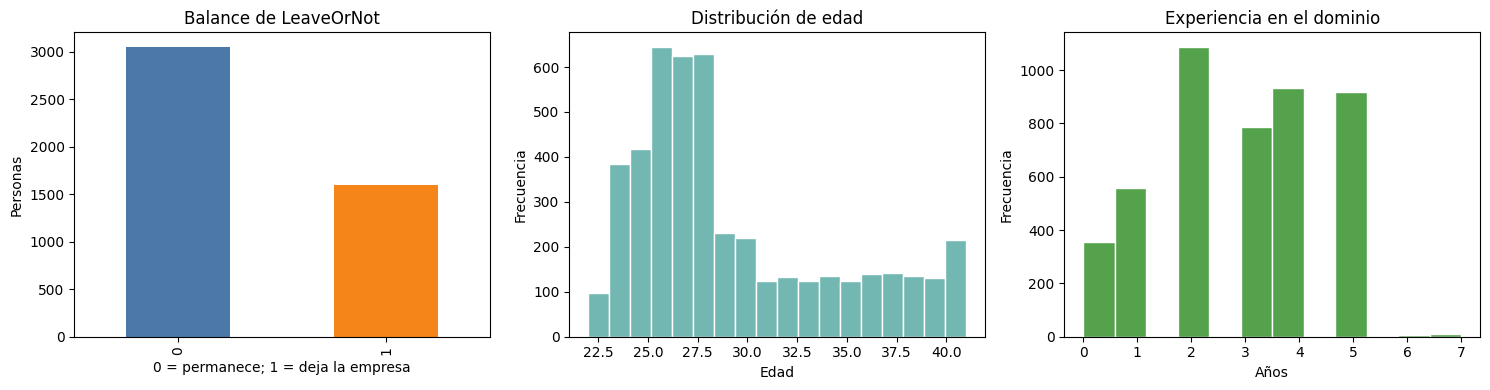

PosixPath('/content/Actividad5/resultados/graficas/01_exploracion_distribuciones.png')

In [4]:
def save_plot(fig, filename):
    path = PLOT_DIR / filename
    fig.savefig(path, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    return path

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df_raw[TARGET_CLASS].value_counts(dropna=False).sort_index().plot(kind='bar', ax=axes[0], color=['#4C78A8','#F58518'])
axes[0].set(title='Balance de LeaveOrNot', xlabel='0 = permanece; 1 = deja la empresa', ylabel='Personas')
df_raw['Age'].plot(kind='hist', bins=18, ax=axes[1], color='#72B7B2', edgecolor='white')
axes[1].set(title='Distribución de edad', xlabel='Edad', ylabel='Frecuencia')
df_raw[TARGET_REG].plot(kind='hist', bins=12, ax=axes[2], color='#54A24B', edgecolor='white')
axes[2].set(title='Experiencia en el dominio', xlabel='Años', ylabel='Frecuencia')
fig.tight_layout(); save_plot(fig, '01_exploracion_distribuciones.png')

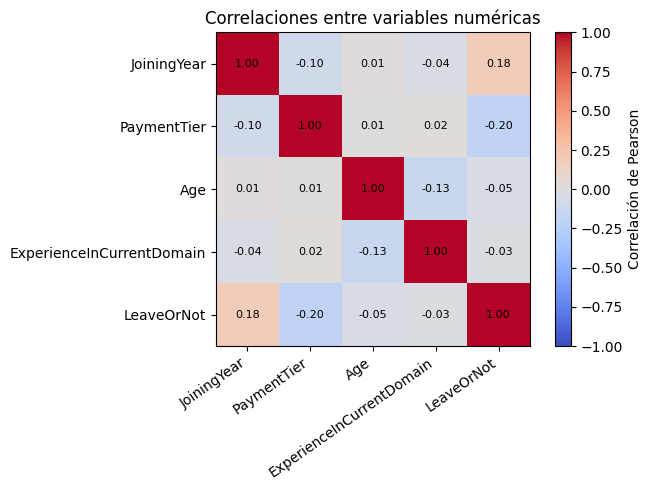

PosixPath('/content/Actividad5/resultados/graficas/02_matriz_correlacion.png')

In [5]:
numeric_cols = ['JoiningYear', 'PaymentTier', 'Age', TARGET_REG, TARGET_CLASS]
corr = df_raw[numeric_cols].apply(pd.to_numeric, errors='coerce').corr()
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=35, ha='right'); ax.set_yticks(range(len(corr.index)), corr.index)
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        if pd.notna(corr.iloc[i,j]): ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=ax, label='Correlación de Pearson'); ax.set_title('Correlaciones entre variables numéricas')
fig.tight_layout(); save_plot(fig, '02_matriz_correlacion.png')

## 4. Limpieza y conjuntos para modelar

Se quitan espacios de nombres/etiquetas categóricas, se convierten a número las variables numéricas, se eliminan duplicados y observaciones incompletas. Las categorías se codificarán con one-hot y las variables numéricas se estandarizarán dentro de cada pipeline de validación cruzada.

La variable de regresión se excluye expresamente de sus propios predictores para evitar *target leakage*. En clasificación sí puede utilizarse como predictor.

In [6]:
df = pd.read_csv(raw_path)
df.columns = df.columns.str.strip()
required = set(FEATURES + [TARGET_CLASS])
missing = required.difference(df.columns)
if missing: raise ValueError(f'Faltan columnas requeridas: {sorted(missing)}')
for col in CATEGORICAL: df[col] = df[col].astype('string').str.strip().str.title()
for col in ['JoiningYear','PaymentTier','Age',TARGET_REG,TARGET_CLASS]: df[col] = pd.to_numeric(df[col], errors='coerce')
rows_before = len(df)
df = df.drop_duplicates().dropna(subset=FEATURES + [TARGET_CLASS]).copy()
df[TARGET_CLASS] = df[TARGET_CLASS].astype(int)
if not df[TARGET_CLASS].isin([0,1]).all(): raise ValueError('LeaveOrNot debe contener solo 0 y 1')
if df.empty: raise ValueError('La limpieza dejó el dataset vacío')
clean_path = CLEAN_DIR / 'employee_dataset_clean.csv'
df.to_csv(clean_path, index=False)
print(f'Filas antes: {rows_before:,}; filas limpias: {len(df):,}; descartadas: {rows_before-len(df):,}')
print('CSV limpio:', clean_path)
display(df.head()); display(df.isna().sum().to_frame('faltantes'))

Filas antes: 4,653; filas limpias: 2,764; descartadas: 1,889
CSV limpio: /content/Actividad5/datos/datos_limp/employee_dataset_clean.csv


,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot
0,Bachelors,2017,Bangalore,3,34,Male,No,0,0
1,Bachelors,2013,Pune,1,28,Female,No,3,1
2,Bachelors,2014,New Delhi,3,38,Female,No,2,0
3,Masters,2016,Bangalore,3,27,Male,No,5,1
4,Masters,2017,Pune,3,24,Male,Yes,2,1


,faltantes
Education,0
JoiningYear,0
City,0
PaymentTier,0
Age,0
Gender,0
EverBenched,0
ExperienceInCurrentDomain,0
LeaveOrNot,0


## 5. Métricas y estrategia de validación

**Clasificación:** accuracy mide aciertos globales; precision mide qué proporción de predicciones de salida fue correcta; recall mide cuántos casos reales de salida detectó el modelo; F1 resume precision y recall; ROC-AUC mide la separación de las clases a distintos umbrales.

**Regresión:** MAE es el error absoluto medio y RMSE penaliza más los errores grandes (ambos en años); R² expresa la variación explicada y puede ser negativo.

Se reserva 20 % para prueba. `GridSearchCV` realiza validación de 5 folds exclusivamente dentro del 80 % de entrenamiento. Para clasificación se emplea `StratifiedKFold` y se optimiza F1; para regresión se usa `KFold` y se optimiza MAE. La codificación y el escalado están dentro de los pipelines, así que se reajustan dentro de cada fold sin filtrar información del fold de validación.

### Seguimiento MLflow con `mlruns`

Este notebook guarda experimentos y corridas en `/content/mlruns` usando el backend de archivos de MLflow. La celda de registro (sección 8) escribe ahí; la celda final de acceso inicia el servidor contra esa misma carpeta. La carpeta vive en el disco temporal de Colab y desaparece al terminar el entorno, así que la última sección permite descargar una copia.

Para abrir la interfaz desde el navegador se usará ngrok. Guarda un Authtoken nuevo en Colab Secrets con el nombre `NGROK_AUTHTOKEN` y activa el acceso del notebook a ese secreto. No escribas el token en una celda ni lo subas a GitHub.


In [7]:
from pathlib import Path
import os
os.environ['MLFLOW_ALLOW_FILE_STORE'] = 'true'  # Compatibilidad con el backend mlruns de archivos
import mlflow
import mlflow.sklearn
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, KFold
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    ConfusionMatrixDisplay, RocCurveDisplay, mean_absolute_error, mean_squared_error, r2_score)
from xgboost import XGBRegressor

# Fuente única de verdad: entrenamiento, validación y UI usan este mismo almacén.
MLFLOW_DIR = Path('/content/mlruns')
MLFLOW_DIR.mkdir(parents=True, exist_ok=True)
TRACKING_URI = MLFLOW_DIR.as_uri()
mlflow.set_tracking_uri(TRACKING_URI)


def make_preprocessor(include_experience=True):
    numeric = ['JoiningYear','PaymentTier','Age'] + ([TARGET_REG] if include_experience else [])
    return ColumnTransformer([
        ('categorical', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL),
        ('numeric', StandardScaler(), numeric),
    ], remainder='drop')

mlflow.set_experiment('Actividad5-Employee-Dataset')
print('Tracking URI activo:', mlflow.get_tracking_uri())


2026/10/18 04:14:29 INFO mlflow.tracking.fluent: Experiment with name 'Actividad5-Employee-Dataset' does not exist. Creating a new experiment.


Tracking URI activo: file:///content/mlruns


## 6. Clasificación: `LeaveOrNot`

El grid compara valores de regularización `C` y ponderación de clases. Se reportan las cinco métricas estandarizadas en el conjunto de prueba y se registran parámetros, métricas, modelo y gráficas en MLflow.

In [8]:
X_cls, y_cls = df[FEATURES], df[TARGET_CLASS]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls)
cv_cls = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pipe_cls = Pipeline([('prep', make_preprocessor()), ('model', LogisticRegression(max_iter=2000))])
grid_cls = GridSearchCV(pipe_cls, {'model__C':[0.1,1.0,10.0], 'model__class_weight':[None,'balanced']}, scoring='f1', cv=cv_cls, n_jobs=-1, refit=True, return_train_score=True)
grid_cls.fit(Xc_train, yc_train)
model_cls = grid_cls.best_estimator_
pred_cls = model_cls.predict(Xc_test); prob_cls = model_cls.predict_proba(Xc_test)[:,1]
metrics_cls = {
 'accuracy': accuracy_score(yc_test,pred_cls),
 'precision': precision_score(yc_test,pred_cls,zero_division=0),
 'recall': recall_score(yc_test,pred_cls,zero_division=0),
 'f1': f1_score(yc_test,pred_cls,zero_division=0),
 'roc_auc': roc_auc_score(yc_test,prob_cls),
}
print('Mejores parámetros:', grid_cls.best_params_); print('F1 CV:', round(grid_cls.best_score_,4))
display(pd.Series(metrics_cls, name='test').to_frame().style.format('{:.4f}'))

Mejores parámetros: {'model__C': 1.0, 'model__class_weight': 'balanced'}
F1 CV: 0.5823


,test
accuracy,0.6745
precision,0.5779
recall,0.6468
f1,0.6104
roc_auc,0.7117


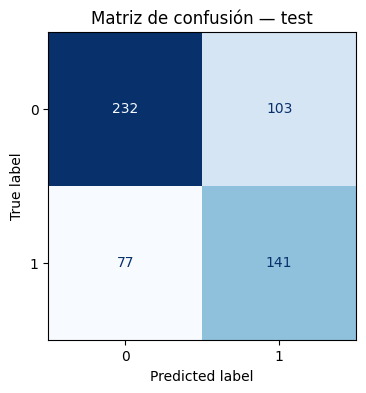

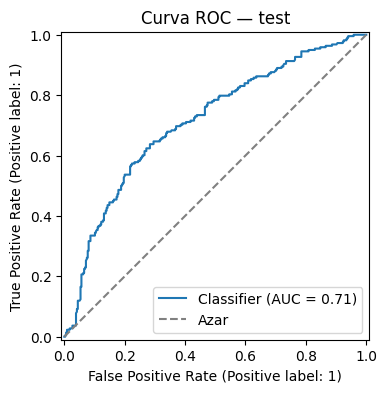

In [9]:
# Evaluación visual de clasificación: matriz de confusión y curva ROC.
fig, ax = plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(yc_test, pred_cls, ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Matriz de confusión — test')
plot_cm = save_plot(fig, '03_clasificacion_matriz_confusion.png')
fig, ax = plt.subplots(figsize=(5,4))
RocCurveDisplay.from_predictions(yc_test, prob_cls, ax=ax)
ax.plot([0,1],[0,1],'--',color='gray',label='Azar'); ax.legend(); ax.set_title('Curva ROC — test')
plot_roc = save_plot(fig, '04_clasificacion_curva_roc.png')

## 7. Regresión: regresión lineal frente a XGBoost

El objetivo es estimar años de experiencia en el dominio usando las demás columnas. Ambos algoritmos se evalúan sobre la misma partición aleatoria y los mismos folds. La búsqueda elige parámetros por menor MAE CV. Esto permite una comparación justa, aunque la variable es discreta y acotada.

In [10]:
reg_features = [c for c in FEATURES if c != TARGET_REG]
X_reg, y_reg = df[reg_features], df[TARGET_REG]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)
cv_reg = KFold(n_splits=5, shuffle=True, random_state=42)
regression_specs = {
 'linear_regression': (Pipeline([('prep', make_preprocessor(False)), ('model', LinearRegression())]), {'model__fit_intercept':[True,False]}),
 'xgboost': (Pipeline([('prep', make_preprocessor(False)), ('model', XGBRegressor(objective='reg:squarederror', random_state=42, n_jobs=1))]), {'model__n_estimators':[100,250], 'model__max_depth':[2,4], 'model__learning_rate':[0.05,0.1]}),
}
regression_results = {}; regression_predictions = {}; fitted_regressors = {}
for name, (pipeline, param_grid) in regression_specs.items():
    search = GridSearchCV(pipeline, param_grid, scoring='neg_mean_absolute_error', cv=cv_reg, n_jobs=-1, refit=True, return_train_score=True)
    search.fit(Xr_train, yr_train)
    pred = search.best_estimator_.predict(Xr_test)
    fitted_regressors[name] = search; regression_predictions[name] = pred
    metrics = {'mae':mean_absolute_error(yr_test,pred), 'rmse':np.sqrt(mean_squared_error(yr_test,pred)), 'r2':r2_score(yr_test,pred)}
    regression_results[name] = {'best_params':search.best_params_, 'cv_mae':float(-search.best_score_), 'test':metrics}
    print(f'\n{name}: parámetros {search.best_params_}; MAE CV={-search.best_score_:.4f}')
display(pd.DataFrame({n:r['test'] for n,r in regression_results.items()}).T.style.format('{:.4f}'))


linear_regression: parámetros {'model__fit_intercept': True}; MAE CV=1.3790

xgboost: parámetros {'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__n_estimators': 100}; MAE CV=0.9573


,mae,rmse,r2
linear_regression,1.3868,1.6200,-0.0018
xgboost,0.9019,1.3205,0.3344


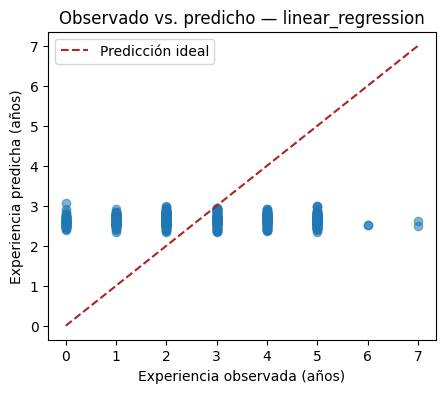

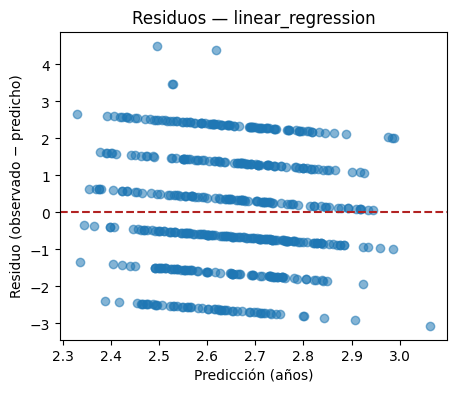

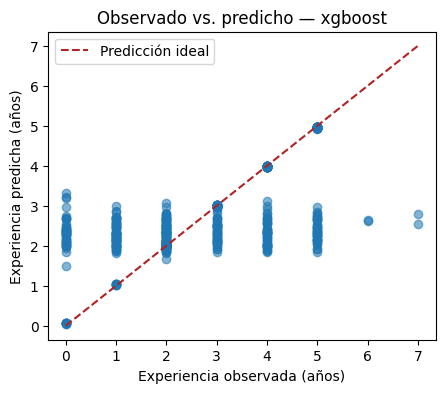

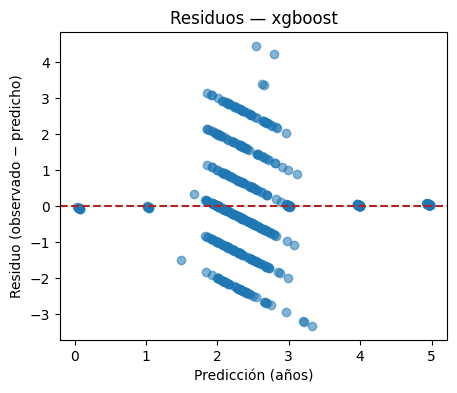

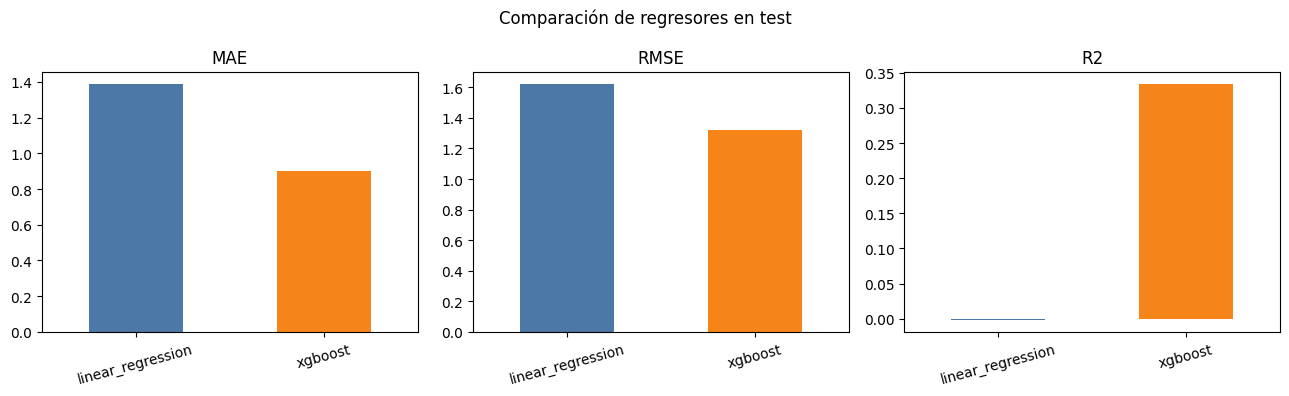

,mae,rmse,r2
linear_regression,1.3868,1.6200,-0.0018
xgboost,0.9019,1.3205,0.3344


In [11]:
# Gráficas de diagnóstico para cada regresor: observado/predicho y residuos.
for name, pred in regression_predictions.items():
    fig, ax = plt.subplots(figsize=(5,4))
    ax.scatter(yr_test, pred, alpha=0.55)
    low, high = min(float(yr_test.min()),float(pred.min())), max(float(yr_test.max()),float(pred.max()))
    ax.plot([low,high],[low,high],'--',color='firebrick',label='Predicción ideal')
    ax.set(xlabel='Experiencia observada (años)',ylabel='Experiencia predicha (años)',title=f'Observado vs. predicho — {name}'); ax.legend()
    save_plot(fig, f'05_{name}_observado_predicho.png')
    fig, ax = plt.subplots(figsize=(5,4))
    ax.scatter(pred, yr_test-pred, alpha=0.55); ax.axhline(0,linestyle='--',color='firebrick')
    ax.set(xlabel='Predicción (años)',ylabel='Residuo (observado − predicho)',title=f'Residuos — {name}')
    save_plot(fig, f'06_{name}_residuos.png')

# Comparación de los errores y R² de prueba.
reg_table = pd.DataFrame({n:r['test'] for n,r in regression_results.items()}).T
fig, axes = plt.subplots(1,3,figsize=(13,4))
for ax, metric in zip(axes,['mae','rmse','r2']):
    reg_table[metric].plot(kind='bar',ax=ax,color=['#4C78A8','#F58518']); ax.set_title(metric.upper()); ax.set_xlabel(''); ax.tick_params(axis='x',rotation=15)
fig.suptitle('Comparación de regresores en test'); fig.tight_layout()
plot_comparison = save_plot(fig,'07_comparacion_regresores.png')
display(reg_table.style.format('{:.4f}').highlight_min(subset=['mae','rmse'],color='#d8f3dc').highlight_max(subset=['r2'],color='#d8f3dc'))

## 8. Registrar experimentos en MLflow

Se crean corridas separadas para el clasificador y cada regresor. Cada corrida registra tarea, objetivo, estrategia de validación, mejor configuración, métrica CV, métricas de test, modelo serializado y gráficas asociadas. La corrida adicional de comparación guarda los resultados de ambos regresores y su figura. El registro al Model Registry se puede habilitar opcionalmente.

In [12]:
REGISTER_MODELS = False  # Cambiar a True si también quieres crear versiones en el Model Registry
trusted_types = [
    'sklearn.compose._column_transformer._RemainderColsList',
    'xgboost.core.Booster',
    'xgboost.sklearn.XGBRegressor'
]

# Aseguramos cerrar cualquier ejecución de MLflow que haya quedado abierta antes de iniciar
if mlflow.active_run():
    mlflow.end_run()

with mlflow.start_run(run_name='classification_logistic_regression'):
    mlflow.log_params({k:str(v) for k,v in {'task':'classification','target':TARGET_CLASS,'cv':'StratifiedKFold(5)','selection_metric':'f1','test_size':0.2,**{f'best_{k}':v for k,v in grid_cls.best_params_.items()}}.items()})
    mlflow.log_metric('cv_best_f1',float(grid_cls.best_score_))
    mlflow.log_metrics({f'test_{k}':float(v) for k,v in metrics_cls.items()})
    for p in [plot_cm,plot_roc]: mlflow.log_artifact(str(p),artifact_path='plots')
    mlflow.sklearn.log_model(model_cls,'model',registered_model_name='EmployeeLeaveClassifier' if REGISTER_MODELS else None, skops_trusted_types=trusted_types)

for name, search in fitted_regressors.items():
    with mlflow.start_run(run_name=f'regression_{name}'):
        mlflow.log_params({k:str(v) for k,v in {'task':'regression','target':TARGET_REG,'cv':'KFold(5)','selection_metric':'MAE','test_size':0.2,**{f'best_{k}':v for k,v in search.best_params_.items()}}.items()})
        mlflow.log_metric('cv_best_mae',float(-search.best_score_))
        mlflow.log_metrics({f'test_{k}':float(v) for k,v in regression_results[name]['test'].items()})
        for p in sorted(PLOT_DIR.glob(f'*{name}*.png')):
            mlflow.log_artifact(str(p),artifact_path='plots')
        mlflow.sklearn.log_model(search.best_estimator_,'model',registered_model_name=f'EmployeeExperience_{name}' if REGISTER_MODELS else None, skops_trusted_types=trusted_types)

with mlflow.start_run(run_name='regression_model_comparison'):
    mlflow.log_param('task','regression_comparison'); mlflow.log_param('target',TARGET_REG)
    for name, result in regression_results.items():
        for metric, value in result['test'].items():
            mlflow.log_metric(f'{name}_test_{metric}',float(value))
    mlflow.log_artifact(str(plot_comparison),artifact_path='plots')
print('Experimentos registrados exitosamente con estado FINISHED. Tracking URI:', mlflow.get_tracking_uri())

2026/10/18 04:14:47 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/18 04:14:55 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/18 04:14:59 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Experimentos registrados exitosamente con estado FINISHED. Tracking URI: file:///content/mlruns


## 9. Validar las corridas y sus artefactos

La siguiente comprobación consulta MLflow directamente. Confirma que existan las corridas esperadas, que cada una tenga parámetros y métricas, y que se hayan guardado tanto un artefacto de modelo (`MLmodel`) como al menos una gráfica (`.png`). Si falta algo, la celda falla con un mensaje claro; si todo está, imprime una tabla de validación.

In [13]:
from mlflow.tracking import MlflowClient
import pandas as pd

client = MlflowClient(tracking_uri=TRACKING_URI)
experiment = client.get_experiment_by_name("Actividad5-Employee-Dataset")

if experiment is None:
    raise RuntimeError(
        "No se encontró el experimento 'Actividad5-Employee-Dataset'. "
        "Ejecuta primero la celda de registro de la sección 8."
    )

runs = client.search_runs(
    [experiment.experiment_id],
    max_results=200,
    order_by=["attributes.start_time DESC"]
)

expected_runs = [
    "classification_logistic_regression",
    "regression_linear_regression",
    "regression_xgboost",
    "regression_model_comparison",
]

def collect_artifacts(run_id, path=""):
    """Lista artefactos de una corrida, incluyendo subcarpetas."""
    found = []
    try:
        for item in client.list_artifacts(run_id, path):
            if item.is_dir:
                found.extend(collect_artifacts(run_id, item.path))
            else:
                found.append(item.path)
    except Exception as exc:
        print(f"No se pudieron leer artefactos de la corrida {run_id}: {exc}")
    return found

# En algunas versiones de MLflow los modelos se consultan como Logged Models.
# Conservamos también la comprobación tradicional del archivo MLmodel.
logged_model_run_ids = set()

if hasattr(client, "search_logged_models"):
    try:
        logged_models = client.search_logged_models(
            experiment_ids=[experiment.experiment_id],
            max_results=200
        )
        logged_model_run_ids = {
            model.source_run_id
            for model in logged_models
            if getattr(model, "source_run_id", None)
        }
    except Exception as exc:
        print(f"No se pudieron consultar los Logged Models de MLflow: {exc}")

validation_rows = []
failures = []

for run_name in expected_runs:
    needs_model = run_name != "regression_model_comparison"
    valid_run = None
    valid_artifacts = []

    # Revisa de la más reciente a la más antigua las corridas con el nombre esperado.
    candidates = [
        run for run in runs
        if run.data.tags.get("mlflow.runName", "") == run_name
    ]

    for run in candidates:
        artifacts = collect_artifacts(run.info.run_id)

        has_params = len(run.data.params) > 0
        has_metrics = len(run.data.metrics) > 0
        has_plot = any(path.lower().endswith(".png") for path in artifacts)
        has_model = (
            any(path.endswith("MLmodel") for path in artifacts)
            or run.info.run_id in logged_model_run_ids
        )

        is_complete = (
            run.info.status == "FINISHED"
            and has_params
            and has_metrics
            and has_plot
            and (not needs_model or has_model)
        )

        if is_complete:
            valid_run = run
            valid_artifacts = artifacts
            break

    if valid_run is None:
        if not candidates:
            failures.append(
                f"- {run_name}: no existe una corrida con ese nombre "
                f"en el experimento."
            )
        else:
            details = []
            for run in candidates:
                artifacts = collect_artifacts(run.info.run_id)
                has_model = (
                    any(path.endswith("MLmodel") for path in artifacts)
                    or run.info.run_id in logged_model_run_ids
                )
                has_plot = any(path.lower().endswith(".png") for path in artifacts)

                details.append(
                    f"estado={run.info.status}, "
                    f"parámetros={len(run.data.params) > 0}, "
                    f"métricas={len(run.data.metrics) > 0}, "
                    f"modelo={has_model if needs_model else 'N/A'}, "
                    f"gráfica={has_plot}, "
                    f"run_id={run.info.run_id}"
                )

            failures.append(
                f"- {run_name}: ninguna corrida cumple todos los requisitos. "
                + " | ".join(details)
            )
        continue

    has_model = (
        any(path.endswith("MLmodel") for path in valid_artifacts)
        or valid_run.info.run_id in logged_model_run_ids
    )
    has_plot = any(path.lower().endswith(".png") for path in valid_artifacts)

    validation_rows.append({
        "corrida": run_name,
        "parámetros": len(valid_run.data.params),
        "métricas": len(valid_run.data.metrics),
        "modelo MLmodel": has_model if needs_model else "N/A",
        "gráfica PNG": has_plot,
        "estado": valid_run.info.status,
    })

if failures:
    print("No se completó la validación:")
    print("\n".join(failures))
    raise AssertionError(
        "Faltan corridas o artefactos. Revisa el detalle anterior y, "
        "si hace falta, vuelve a ejecutar la celda de registro de la sección 8."
    )

display(pd.DataFrame(validation_rows).set_index("corrida"))
print(
    "Validación correcta: MLflow contiene parámetros, métricas, "
    "modelos y gráficas para todas las corridas esperadas."
)

,parámetros,métricas,modelo MLmodel,gráfica PNG,estado
corrida,,,,,
classification_logistic_regression,7,6,True,True,FINISHED
regression_linear_regression,6,4,True,True,FINISHED
regression_xgboost,8,4,True,True,FINISHED
regression_model_comparison,2,6,N/A,True,FINISHED


Validación correcta: MLflow contiene parámetros, métricas, modelos y gráficas para todas las corridas esperadas.


## 10. Abrir la interfaz, guardar y descargar resultados

Crear un túnel temporal de ngrok y un servidor MLflow que lee `/content/mlruns`.


In [18]:
# Abre MLflow en Colab. Ejecuta después de la sección 9.
import subprocess, time, requests
from urllib.parse import urlparse
from google.colab import userdata
from pyngrok import ngrok

PORT = 5001  # evita chocar con servidores anteriores que quizá sigan en 5000
TOKEN = userdata.get('NGROK_AUTHTOKEN')
if not TOKEN:
    raise RuntimeError('Falta el secreto NGROK_AUTHTOKEN. Agrégalo en Colab > Secrets y habilita el acceso para este notebook.')

# Recupera el proceso/túnel si se vuelve a ejecutar esta celda.
ngrok.kill()
ngrok.set_auth_token(TOKEN)
tunnel = ngrok.connect(f'127.0.0.1:{PORT}', 'http')
public_url = tunnel.public_url
public_host = urlparse(public_url).netloc
print('URL de MLflow:', public_url)

server_log_path = '/content/mlflow_server.log'
server_log = open(server_log_path, 'w')
server_proc = subprocess.Popen([
    'mlflow', 'server',
    '--backend-store-uri', TRACKING_URI,
    '--host', '0.0.0.0',
    '--port', str(PORT),
    '--workers', '1',
    '--allowed-hosts', public_host,
    '--cors-allowed-origins', public_url,
], stdout=server_log, stderr=subprocess.STDOUT)

# Espera hasta 45 s a que la interfaz responda.
for _ in range(45):
    if server_proc.poll() is not None:
        server_log.flush()
        print(open(server_log_path).read()[-5000:])
        raise RuntimeError('El servidor MLflow terminó al iniciar; revisa el registro anterior.')
    try:
        response = requests.get(f'http://127.0.0.1:{PORT}/health', timeout=1)
        if response.ok:
            print('MLflow listo. Abre la URL anterior; mantén esta sesión de Colab activa.')
            break
    except requests.RequestException:
        pass
    time.sleep(1)
else:
    server_log.flush()
    print(open(server_log_path).read()[-5000:])
    raise TimeoutError('MLflow no respondió en 45 s; revisa el registro anterior.')


URL de MLflow: https://slather-satisfy-lazy.ngrok-free.dev
MLflow listo. Abre la URL anterior; mantén esta sesión de Colab activa.


## 11. Empaquetar una copia de resultados

La carpeta `mlruns` contiene los metadatos de experimentos y las corridas, además de los artefactos. El ZIP puede crecer según los modelos y gráficas registrados.

In [ ]:
import zipfile
from google.colab import files

summary = {
    'classification': {
        'best_params': grid_cls.best_params_,
        'cv_f1': float(grid_cls.best_score_),
        'test': {k: float(v) for k, v in metrics_cls.items()},
    },
    'regression': regression_results,
}
results_path = PROJECT / 'resultados.json'
results_path.write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')

bundle_path = PROJECT / 'resultados_actividad5.zip'
with zipfile.ZipFile(bundle_path, 'w', zipfile.ZIP_DEFLATED) as bundle:
    bundle.write(results_path, arcname='resultados.json')
    for image_path in PLOT_DIR.glob('*.png'):
        bundle.write(image_path, arcname=f'graficas/{image_path.name}')
    for path in MLFLOW_DIR.rglob('*'):
        if path.is_file():
            bundle.write(path, arcname=str(Path('mlruns') / path.relative_to(MLFLOW_DIR)))

print('ZIP listo:', bundle_path)
files.download(str(bundle_path))
